# 04 · Pairs trading: does cointegration hold out of sample?

**The idea.** Find two securities whose prices move together. When they drift apart, buy the cheap one, short the rich one, and wait for the gap to close. The position is market-neutral, and the profit comes from convergence.

**The evidence.** Gatev, Goetzmann and Rouwenhorst (*Pairs Trading*, Review of Financial Studies 2006) found that simple pairs on US stocks earned about 11% a year in 1962–2002. Later work (Do and Faff 2010) found the profits shrinking.

**The question here** is the assumption underneath: that a pair which moved together in the past will keep doing so. Pairs can be chosen two ways:
- **Distance:** the pairs whose normalized prices tracked each other most closely over the past year. No model.
- **Cointegration (Engle-Granger):** pairs whose price spread passes a statistical test for mean reversion. This is the textbook approach, and it makes a testable claim: the relationship is stable.

**Two universes, chosen for opposite reasons:**

| | Stocks | Industries |
|---|---|---|
| What | 56 large US stocks in software, utilities, banks, energy; pairs only within a sector | French's 49 industry portfolios; any two |
| Period | 2005–2026 (daily) | 1970–2026 (daily) |
| Survivorship | **Biased**: today's survivors | **None**: industries don't disappear |

The stock list shows the bias directly. Yahoo Finance no longer has prices for **Silicon Valley Bank and First Republic** (both failed in 2023), or for ANSYS, Citrix, VMware, Hess, Marathon Oil, Pioneer and Comerica (all acquired). A pairs strategy is especially exposed to this: it *buys* whichever stock has fallen behind its partner, which is exactly what a failing bank does on its way to zero.

**Design, fixed before running** (following Gatev et al.):
- **Formation:** 12 months. Pick the 20 best pairs (lowest distance, or lowest cointegration p-value, below 0.05).
- **Trading:** the next 6 months. Open when the spread is more than 2 standard deviations from its formation mean (both measured in formation only). Close when it crosses back, or at the end of the 6 months.
- **Sizing:** $1 long and $1 short per trade. Each pair is allotted $1 of capital whether it trades or not ("committed capital").
- **Timing:** a new portfolio starts every month, so six overlap at any time; the strategy return is their average.
- **Costs:** 10 bps per leg traded and 50 bps a year to borrow the short leg, in the "net" runs.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from quant_research.backtest import metrics as mt
from quant_research.data import french, prices
from quant_research.factors import model
from quant_research.pairs import selection as sel
from quant_research.pairs.trading import Spec, run

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams.update({"figure.figsize": (10, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 110})
pct = plt.FuncFormatter(lambda x, _: f"{x:.0%}")

GROUPS = {
    "software": "MSFT ORCL ADBE CRM INTU ADSK CDNS SNPS AKAM IBM ACN CHKP OTEX PTC TYL".split(),
    "utilities": "DUK SO AEP D XEL ED EXC PEG WEC ES DTE ETR AEE CMS CNP NI PPL".split(),
    "banks": "JPM BAC C WFC USB PNC TFC KEY FITB RF MTB HBAN ZION".split(),
    "energy": "XOM CVX COP OXY EOG DVN APA MUR HAL SLB BKR".split(),
}
SECTOR = {t: g for g, ts in GROUPS.items() for t in ts}
stocks = pd.concat({t: prices.daily_prices(t, start="2004-01-01") for t in SECTOR}, axis=1)
industries = (1 + french.load("ind49_daily").loc["1969-01-01":]).cumprod()      # price indexes from daily returns
print(f"Stocks: {stocks.shape[1]} names, {stocks.index.min():%Y-%m-%d} to {stocks.index.max():%Y-%m-%d}; "
      f"missing prices: {stocks.isna().sum()[lambda s: s > 0].to_dict()} (Salesforce before its 2004 IPO)")
print(f"Industries: {industries.shape[1]}, {industries.index.min():%Y-%m-%d} to {industries.index.max():%Y-%m-%d}")

Stocks: 56 names, 2004-01-02 to 2026-10-30; missing prices: {'CRM': 118} (Salesforce before its 2004 IPO)
Industries: 49, 1969-01-02 to 2026-09-30


## 1 · Results

In [2]:
universes = {"Stocks": (stocks, GROUPS, None), "Industries": (industries, None, "1970-01-01")}
runs = {}
for uname, (px, groups, start) in universes.items():
    for method in ("distance", "cointegration"):
        for label, cost, borrow in (("gross", 0, 0), ("net", 10, 50)):
            runs[(uname, method, label)] = run(px, Spec(method=method, cost_bps=cost, borrow_bps=borrow), groups, start)

monthly = {k: (1 + v[0]).resample("ME").prod() - 1 for k, v in runs.items()}
rows = {}
for (u, m, label), r in monthly.items():
    s = mt.summary(r)
    trades = runs[(u, m, label)][2]
    rows[(u, m, label)] = {"period": f"{s['start']}–{s['end']}", "return / yr": s["return / yr"], "volatility": s["volatility"],
                           "Sharpe": s["Sharpe"], "t": s["t (mean)"], "max drawdown": s["max drawdown"],
                           "trades": len(trades), "% converged": trades["converged"].mean()}
results = pd.DataFrame(rows).T
results

period return / yr volatility Sharpe  \
Stocks     distance      gross  2005-01–2026-10       0.003      0.032  0.101   
                         net    2005-01–2026-10      -0.010      0.032 -0.310   
           cointegration gross  2005-01–2026-10       0.043      0.053  0.813   
                         net    2005-01–2026-10       0.028      0.052  0.544   
Industries distance      gross  1970-01–2026-09      -0.006      0.031 -0.205   
                         net    1970-01–2026-09      -0.021      0.031 -0.669   
           cointegration gross  1970-01–2026-09      -0.005      0.051 -0.096   
                         net    1970-01–2026-09      -0.021      0.051 -0.403   

                                    t max drawdown trades % converged  
Stocks     distance      gross  0.473       -0.094   6431       0.379  
                         net   -1.450       -0.261   6431       0.379  
           cointegration gross  3.801       -0.086   7319       0.472  
                         net    2.543       -0.120   7319       0.472  
Industries distance      gross -1.542       -0.413  18429       0.404  
                         net   -5.042       -0.715  18429       0.404  
           cointegration gross -0.723       -0.333  20358       0.452  
                         net   -3.034       -0.714  20358       0.452

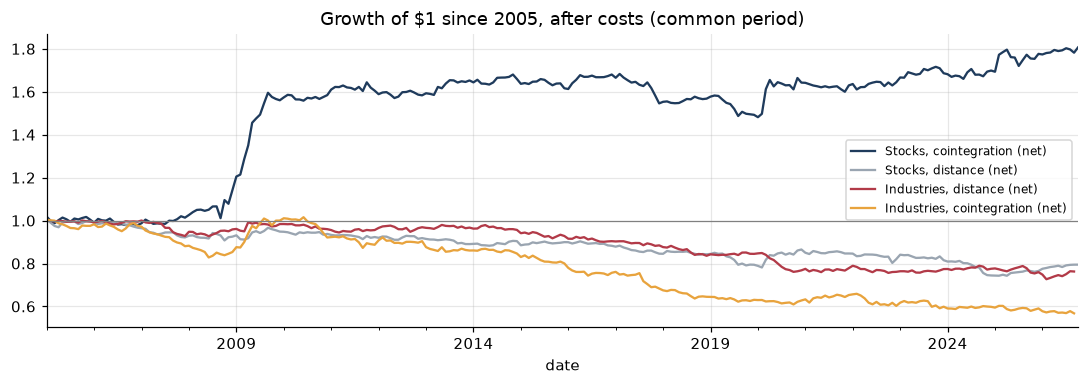

In [3]:
fig, ax = plt.subplots()
for key, c, lbl in (((("Stocks", "cointegration", "net")), "#1f3b5c", "Stocks, cointegration (net)"),
                    ((("Stocks", "distance", "net")), "#9aa5b1", "Stocks, distance (net)"),
                    ((("Industries", "distance", "net")), "#b23a48", "Industries, distance (net)"),
                    ((("Industries", "cointegration", "net")), "#e8a33d", "Industries, cointegration (net)")):
    r = monthly[key]["2005":]
    (1 + r).cumprod().plot(ax=ax, color=c, lw=1.5, label=lbl)
ax.axhline(1, color="grey", lw=0.8)
ax.set_title("Growth of $1 since 2005, after costs (common period)")
ax.legend(fontsize=8)
plt.tight_layout()

- **Only one of the four makes money: cointegration on stocks.** It earned about 4% a year before costs (Sharpe 0.8) and about 3% after.
- **Distance pairs on stocks earned almost nothing**, even before costs. The original method no longer works on these names.
- **Industry pairs lost money over 56 years with both methods**, even before costs.
- **About 40–47% of trades converge.** The rest are closed at the end of six months, usually at a loss. Every strategy depends on the converging minority.

## 2 · Has it decayed?

In [4]:
eras = (("1970", "1989"), ("1990", "2004"), ("2005", "2014"), ("2015", "2026"))
pd.DataFrame({f"{u}, {m}": {f"{a}–{b}": monthly[(u, m, "gross")][a:b].mean() * 12 if len(monthly[(u, m, "gross")][a:b]) else np.nan
                            for a, b in eras}
              for u in universes for m in ("distance", "cointegration")}).T.style.format("{:+.1%}", na_rep="—")

,1970–1989,1990–2004,2005–2014,2015–2026
"Stocks, distance",—,—,+0.3%,+0.3%
"Stocks, cointegration",—,—,+6.7%,+2.2%
"Industries, distance",-2.1%,-0.0%,+1.0%,-0.4%
"Industries, cointegration",-1.5%,+1.4%,-0.0%,-1.7%


For stocks with cointegration, the gross return fell by two-thirds, from 6.7% a year in 2005–14 to about 2% since. After 10 bps a leg, about 1% a year is left since 2015.

The growth chart above suggests something sharper: most of the stock strategy's gain came in one episode, 2008–09.

In [5]:
rows = {}
for label in ("gross", "net"):
    m = monthly[("Stocks", "cointegration", label)]
    crisis = m["2008-07":"2009-12"]
    rest = m.drop(crisis.index)
    rows[label] = {"2008-07 to 2009-12, cumulative": (1 + crisis).prod() - 1,
                   "all other months, return / yr": rest.mean() * 12,
                   "all other months, t": rest.mean() / rest.std() * len(rest) ** 0.5}
pd.DataFrame(rows).T.style.format({"2008-07 to 2009-12, cumulative": "{:+.0%}", "all other months, return / yr": "{:+.1%}",
                                   "all other months, t": "{:.1f}"})

,"2008-07 to 2009-12, cumulative","all other months, return / yr","all other months, t"
gross,+53%,+2.5%,2.9
net,+49%,+1.0%,1.2


The 18 months of the financial crisis returned about +50%. In every other month the strategy earned about 2.5% a year before costs, still significant, but about 1% after costs, which is not (t ≈ 1.2). Pairs trading pays when markets are dislocated, volatility is high and spreads blow out and then snap back. In normal markets, at realistic costs, these stock pairs earned close to nothing. This is the decline Do and Faff documented, and it continued.

## 3 · What is it exposed to?

Pairs trading buys recent losers and sells recent winners *within a pair*, so it should look like a **reversal** strategy and be **short momentum**. The regression adds French's short-term reversal factor (last month's losers minus winners) to the six factors from study 01.

In [6]:
f = french.factors().join(french.load("strev").rename(columns={"ST_Rev": "STRev"}))
terms = model.FF5_MOM + ["STRev"]
reg = {}
for u in universes:
    for m in ("distance", "cointegration"):
        fit = model.fit(monthly[(u, m, "gross")], f, terms)
        reg[f"{u}, {m}"] = {"alpha / yr": fit.alpha_annual, "t(alpha)": fit.alpha_t, "R²": fit.r2,
                            "Mom": fit.table.at["Mom", "coef"], "t(Mom)": fit.table.at["Mom", "t"],
                            "STRev": fit.table.at["STRev", "coef"], "t(STRev)": fit.table.at["STRev", "t"]}
pd.DataFrame(reg).T

,alpha / yr,t(alpha),R²,Mom,t(Mom),STRev,t(STRev)
"Stocks, distance",0.005,0.754,0.103,-0.060,-4.205,0.033,1.645
"Stocks, cointegration",0.051,3.472,0.155,-0.144,-3.202,0.021,0.566
"Industries, distance",-0.002,-0.628,0.283,-0.092,-10.688,0.062,5.264
"Industries, cointegration",0.001,0.081,0.129,-0.102,-4.117,0.020,0.721


- **Industry pairs lose because they bet against momentum.** Study 02 showed that industries trend: the leaders over the past year keep leading. An industry pairs trade buys the industry that fell behind and shorts the one that pulled ahead, which is the opposite of industry momentum. The momentum loading is strongly negative (t ≈ −10), and once it is accounted for the alpha is zero.
- **Stock pairs are also short momentum**, but cointegration-selected stock pairs keep an alpha of about 5% a year (t ≈ 3.5) after all seven factors. Market-wide reversal (STRev) explains almost none of it. What remains is reversal *within* matched stocks, which is not the same as reversal across the whole market.

## 4 · Does cointegration persist?

This is the assumption the method rests on. Every quarter, test all within-sector stock pairs (374 when every stock has a full year of data) on the past 12 months and again on the next 12 months.

,average over all quarters
cointegrated now,8.6%
still cointegrated next year,9.3%
base rate next year (all pairs),8.6%
"the 20 strongest, next year",9.6%
hedge ratio change (median),46.0%


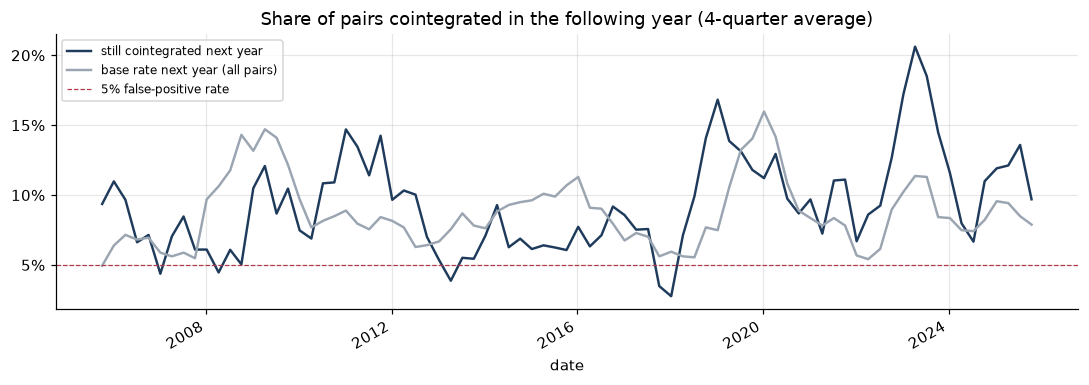

In [7]:
days = stocks.index
rows = []
for s in range(252, len(days) - 252, 63):
    form = stocks.iloc[s - 252:s].dropna(axis=1)
    nxt = stocks.iloc[s:s + 252][form.columns].ffill()
    pairs = sel.candidate_pairs(GROUPS, list(form.columns))
    j = sel.cointegration(form, pairs).join(sel.cointegration(nxt, pairs), rsuffix="_next")
    now = j["p"] < 0.05
    rows.append({"date": days[s], "pairs tested": len(j), "cointegrated now": now.mean(),
                 "still cointegrated next year": (j.loc[now, "p_next"] < 0.05).mean(),
                 "base rate next year (all pairs)": (j["p_next"] < 0.05).mean(),
                 "the 20 strongest, next year": (j.sort_values("p").head(20)["p_next"] < 0.05).mean(),
                 "hedge ratio change (median)": (j.loc[now, "beta_next"] / j.loc[now, "beta"] - 1).abs().median()})
stability = pd.DataFrame(rows).set_index("date")
display(stability.drop(columns="pairs tested").mean().to_frame("average over all quarters").style.format("{:.1%}"))

ax = stability[["still cointegrated next year", "base rate next year (all pairs)"]].rolling(4).mean().plot(color=["#1f3b5c", "#9aa5b1"], lw=1.6)
ax.axhline(0.05, color="#b23a48", lw=0.8, ls="--", label="5% false-positive rate")
ax.yaxis.set_major_locator(plt.MultipleLocator(0.05))
ax.yaxis.set_major_formatter(pct)
ax.set_title("Share of pairs cointegrated in the following year (4-quarter average)")
ax.legend(fontsize=8)
plt.tight_layout()

**It doesn't persist.** A pair that is cointegrated this year is cointegrated next year about 9% of the time, which is the same rate as any random pair in the same sector (also about 9%). Even the 20 strongest pairs do no better. The hedge ratio, meaning how many dollars of one stock offset a dollar of the other, typically changes by over 40% from one year to the next.

In other words, the test isn't finding stable relationships. With 374 pairs tested and a 5% false-positive rate, about 19 pass by chance alone every year. The observed 8–9% is only a little above that.

**So why does cointegration selection still earn more than distance?** It is the one positive result, and it isn't the reason the method assumes. The test picks pairs whose spread reverted *quickly in the past year*, and fast short-term reversal within an industry is a known effect (Da, Liu and Schaumburg 2014) that is distinct from long-run cointegration. The sector mix, shown below, is part of it too.

In [8]:
mix = {}
for m in ("distance", "cointegration"):
    picks, trades = runs[("Stocks", m, "gross")][1], runs[("Stocks", m, "gross")][2]
    share = picks["a"].map(SECTOR).value_counts(normalize=True)
    per_slot = trades.groupby(trades["a"].map(SECTOR))["pnl"].sum() / picks.groupby(picks["a"].map(SECTOR)).size()
    mix[m] = pd.DataFrame({"share of selections": share, "P&L per selected pair": per_slot})
pd.concat(mix, axis=1).style.format("{:.1%}")

Distance selection picks **utilities** 78% of the time: they are the stocks that move together most closely, so their spreads are too small to earn much after costs. Cointegration spreads its picks across sectors, and its bank and software pairs earn the most.

## 5 · Trades that don't converge

,count,mean,50%,min,max
converged,,,,,
False,3864.000,-0.038,-0.027,-1.033,3.551
True,3455.000,0.064,0.049,-0.538,0.925


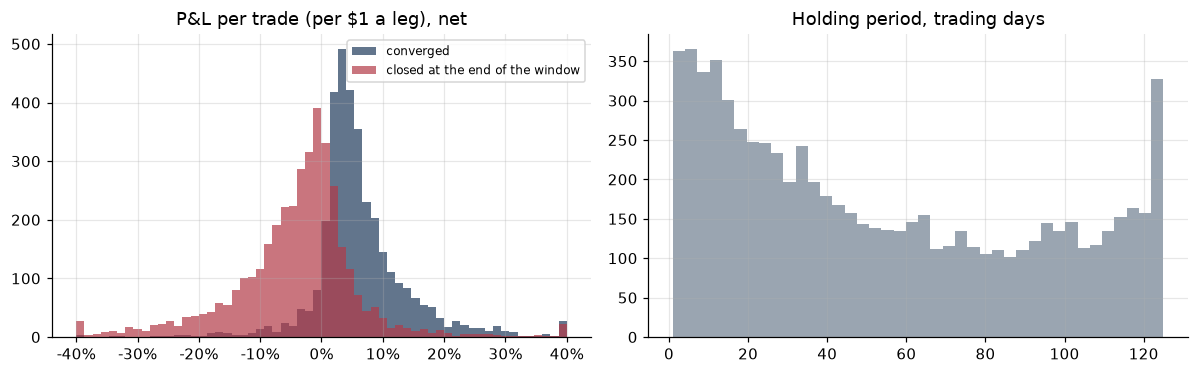

In [9]:
trades = runs[("Stocks", "cointegration", "net")][2]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for conv, c, lbl in ((True, "#1f3b5c", "converged"), (False, "#b23a48", "closed at the end of the window")):
    axes[0].hist(trades.loc[trades["converged"] == conv, "pnl"].clip(-0.4, 0.4), bins=60, alpha=0.7, color=c, label=lbl)
axes[0].xaxis.set_major_formatter(pct)
axes[0].set_title("P&L per trade (per $1 a leg), net")
axes[0].legend(fontsize=8)
axes[1].hist(trades["days"], bins=40, color="#9aa5b1")
axes[1].set_title("Holding period, trading days")
plt.tight_layout()
trades.groupby("converged")["pnl"].describe()[["count", "mean", "50%", "min", "max"]]

The profile of a short-volatility strategy. Converging trades earn about 6% on average. Trades that don't converge lose about 4% on average, with a long left tail in which a single trade can lose its whole $1. The strategy wins about half the time and depends on keeping the losers small.

### A design flaw, and the fix

Some *converged* trades lost money (see the minimum above), which shouldn't happen. The cointegration spread is log A − β·log B, but the pre-set design holds $1 of each stock, which matches the spread only when β ≈ 1. If β is far from 1, the spread can close while the $1/$1 position loses. The fix sizes the legs 1 : β, keeping the same $2 gross so returns stay comparable.

In [10]:
rows = {}
for u, (px, groups, start) in universes.items():
    for hedge in ("dollar", "beta"):
        for label, cost, borrow in (("gross", 0, 0), ("net", 10, 50)):
            daily, _, tr = runs[(u, "cointegration", label)] if hedge == "dollar" else run(
                px, Spec(method="cointegration", hedge=hedge, cost_bps=cost, borrow_bps=borrow), groups, start)
            m = (1 + daily).resample("ME").prod() - 1
            conv = tr[tr["converged"]]
            rows[(u, hedge, label)] = {"return / yr": m.mean() * 12, "Sharpe": m.mean() / m.std() * 12 ** 0.5,
                                       "2015–26 / yr": m["2015":].mean() * 12,
                                       "converged trades that lost": (conv["pnl"] < 0).mean()}
pd.DataFrame(rows).T.style.format({"return / yr": "{:+.1%}", "Sharpe": "{:.2f}", "2015–26 / yr": "{:+.1%}",
                                   "converged trades that lost": "{:.1%}"})

Sizing the legs by β removes the problem: converged trades that lose money fall from about 9% to almost none. The results barely change, though: stock pairs still earn about 4% a year gross and about 1% net since 2015, and industry pairs still lose. The conclusions don't depend on the flaw.

## 6 · What survivorship hides

The bank pairs show it. Below are the worst bank trades open in March 2023, when Silicon Valley Bank and First Republic failed and regional banks fell sharply.

In [11]:
banks = trades[trades["a"].map(SECTOR) == "banks"]
march = banks[(banks["open"] <= "2023-03-31") & (banks["close"] >= "2023-03-08")]
display(march[["a", "b", "open", "close", "side", "converged", "pnl"]].sort_values("pnl").head(6))
worst = monthly[("Stocks", "cointegration", "net")].nsmallest(3)
print("Worst months of the strategy:", {f"{d:%Y-%m}": f"{v:.1%}" for d, v in worst.items()})

,a,b,open,close,side,converged,pnl
6078,WFC,ZION,2022-10-13,2023-04-11,-1,False,-0.342
6056,JPM,USB,2022-09-22,2023-03-10,-1,False,-0.263
6045,WFC,ZION,2022-10-14,2023-03-10,-1,False,-0.159
6092,C,PNC,2023-01-19,2023-04-11,-1,False,-0.144
6107,KEY,FITB,2023-03-13,2023-05-10,1,False,-0.120
6066,BAC,PNC,2023-03-02,2023-04-11,-1,False,-0.047


Worst months of the strategy: {'2008-09': '-5.2%', '2017-12': '-2.3%', '2025-07': '-2.2%'}


Even among the survivors, March 2023 produced the largest trade losses in the bank sector. Now the counterfactual. Had SVB or First Republic been in the universe, the rule would have bought it: it fell far behind its partner in the weeks before it failed, which is precisely the signal to buy the cheap leg. A $1 long position going to zero, in one of 20 pairs on committed capital, is a **5% loss to the whole portfolio** in a few days. That equals the strategy's worst month in 22 years (September 2008).

A survivor-only backtest cannot show this, so the stock results above are an upper bound. The industry results don't have this problem, and they show no profit at all.

## Conclusions

| Question | Answer |
|---|---|
| Does pairs trading work? | Only cointegration-selected **stocks**: 4.3% a year gross, 2.8% net (t 2.5), on a survivor-biased universe, and about 1% net since 2015. Distance-selected stocks earn ~0; industries lose money with both methods |
| Has it decayed? | Yes. Stock cointegration fell from 6.7% a year (2005–14) to about 2% (2015–26), before costs. 2008–09 alone returned about +50%; all other months earned about 1% a year after costs, not significant |
| Does cointegration persist? | **No.** 9% of cointegrated pairs are still cointegrated a year later, the same as any random pair. Hedge ratios move over 40% |
| Then where does the profit come from? | Fast reversal within matched stocks (alpha ~5% after seven factors), not a stable long-run relation |
| Why do industry pairs lose? | They bet against industry momentum (study 02): momentum t ≈ −10, alpha zero |
| Main risk | Non-converging trades, and survivorship. A failing stock is exactly what the rule buys, and one failed bank would cost about 5% |
| Design check | Holding $1 of each stock mismatches the cointegration spread when β ≠ 1. Sizing the legs 1 : β fixes it and changes nothing above |

**For a quant team:** treat a cointegration test as a filter for recent mean reversion, not as evidence of a lasting relationship. Re-estimate often, cap the loss on non-converging trades, and test on a universe that includes delisted names (CRSP) before allocating capital.